This notebook checks that Gmesh **trains**: gradients flow through the hybrid renderer to the 3D Gaussians *and* to the mesh, with correct occlusions between them.

**Ground truth.** The example mesh (spot) with shaded vertex colors, plus two rings of colorful Gaussians that pass *through* the mesh: parts of the rings are in front of it, parts behind it, and parts cross its surface. The scene is rendered from 24 orbit views (training) and 6 other views (testing).

**Experiments.** Starting from perturbed parameters, we optimize with Adam and an L1 photometric loss:

1. **Gaussians**: means, rotations, scales, opacities, colors (the fixed mesh occludes them).
2. **Mesh**: a translation of the mesh and its vertex colors (the Gaussians are fixed). The gradients come through the antialiased silhouettes, the mesh depth vs. the Gaussians (soft depth test), and the color interpolation.
3. **Joint**: both at once.

The scene and parameter helpers are shared with the script version, `examples/train_toy.py`.

In [1]:
## Computing Device
device = 'cuda:0'
import torch
torch.cuda.set_device(device)

import os, sys, math, time
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, os.path.abspath('..'))  # the repository root (this notebook runs from ./examples)
sys.path.insert(0, os.path.abspath('.'))   # ./examples, for train_toy.py

from gmesh.scenes.cameras import OrbitCamera
from gmesh.renderer.gmesh_renderer import GmeshRenderer
from train_toy import (load_mesh, ground_truth_gaussians, perturbed_gaussians, make_gaussians,
                       make_mesh, orbit_poses, render_rgb, psnr)

torch.manual_seed(0)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


### Create the ground-truth scene and the renderer

The camera orbits the scene; a camera pose is `(elevation, azimuth, distance)`.

In [2]:
IMAGE_SIZE = 256

vertices, faces, gt_mesh_colors = load_mesh(device)               # spot mesh with shaded vertex colors
gt_gaussian_params = ground_truth_gaussians(n_per_ring=1500, device=device)  # raw (unactivated) parameters
gt_mesh_params = {
    'translation': torch.zeros(3, device=device),
    'color_logits': torch.logit(gt_mesh_colors),
}

camera = OrbitCamera(image_width=IMAGE_SIZE, image_height=IMAGE_SIZE, fov_x=40, fov_y=40,
                     z_near=0.1, z_far=100, device=device)
renderer = GmeshRenderer(camera=camera, tile_size=16, bg_color=(1.0, 1.0, 1.0))

train_poses, test_poses = orbit_poses(device)   # 24 training views, 6 test views
print(f'mesh: {vertices.shape[0]} vertices, {faces.shape[0]} faces')
print(f'Gaussians: {gt_gaussian_params["means"].shape[0]}')
print(f'{len(train_poses)} training views, {len(test_poses)} test views')

mesh: 2930 vertices, 5856 faces
Gaussians: 3000
24 training views, 6 test views


### Look at the ground truth

From left to right: the mesh alone, the Gaussians alone (plain 3DGS, no occlusion), and the hybrid rendering (Gmesh): the rings disappear behind the mesh, appear in front of it, and are cut smoothly where they cross its surface.

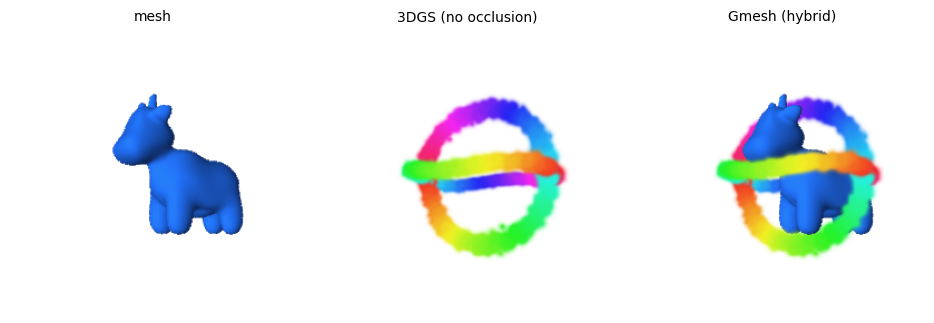

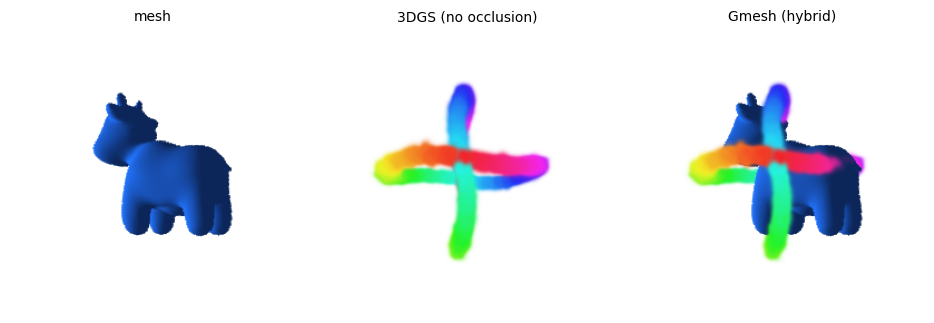

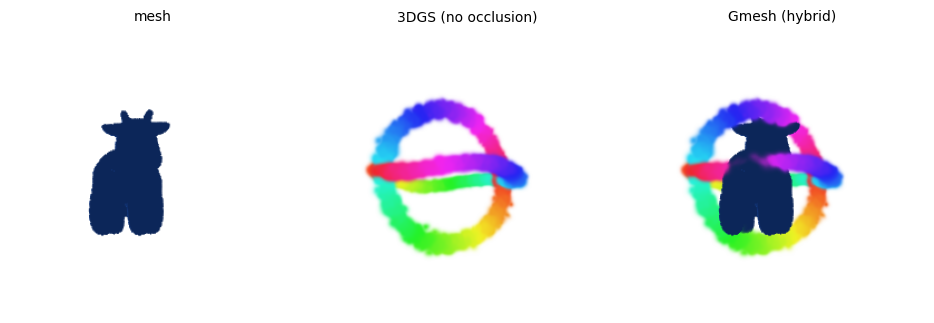

In [3]:
def to_np(img):
    return img.detach().clamp(0, 1).cpu().numpy()

def show_images(images, titles, size=3.2):
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(to_np(img))
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

with torch.no_grad():
    gt_mesh = make_mesh(vertices, faces, gt_mesh_params)
    gt_gaussians = make_gaussians(gt_gaussian_params)
    for pose in test_poses[:3]:
        ret = renderer.render(mesh=gt_mesh, gaussians=gt_gaussians, camera_pose=pose, return_all=True)
        show_images([ret['mesh'][0][0], ret['3dgs'][0][0], ret['blend'][0][0]],
                    ['mesh', '3DGS (no occlusion)', 'Gmesh (hybrid)'])

    # ground-truth images for training and testing
    gt_train = [render_rgb(renderer, gt_mesh, gt_gaussians, pose) for pose in train_poses]
    gt_test = [render_rgb(renderer, gt_mesh, gt_gaussians, pose) for pose in test_poses]

### Sanity check: gradients reach everything

One forward/backward pass from perturbed parameters, through the hybrid renderer. Every trainable quantity (Gaussians and mesh) should receive a non-zero, finite gradient.

In [4]:
g_params = {k: v.clone().requires_grad_(True) for k, v in perturbed_gaussians(gt_gaussian_params, device).items()}
m_params = {'translation': torch.tensor([0.12, -0.08, 0.10], device=device).requires_grad_(True),
            'color_logits': torch.zeros_like(gt_mesh_colors).requires_grad_(True)}

rgb = render_rgb(renderer, make_mesh(vertices, faces, m_params), make_gaussians(g_params), train_poses[0])
loss = (rgb - gt_train[0]).abs().mean()
loss.backward()

for name, p in list(g_params.items()) + list(m_params.items()):
    g = p.grad
    print(f'{name:15s} grad norm {g.norm().item():.3e}   finite: {bool(torch.isfinite(g).all())}')

means           grad norm 1.410e-02   finite: True
quats           grad norm 4.188e-10   finite: True
log_scales      grad norm 9.661e-04   finite: True
opacity_logits  grad norm 4.250e-04   finite: True
sh              grad norm 7.238e-04   finite: True
translation     grad norm 1.576e-02   finite: True
color_logits    grad norm 4.796e-04   finite: True


### Training loop

`train()` optimizes the selected parameters with Adam (learning rates decay by 10x over the run). Every `snapshot_every` iterations it records the test PSNR (and the mesh translation error) and a rendering of the first test view.

In [5]:
LEARNING_RATES = {
    'means': 2e-3, 'quats': 1e-2, 'log_scales': 1e-2, 'opacity_logits': 5e-2, 'sh': 2e-2,  # Gaussians
    'translation': 2e-3, 'color_logits': 5e-2,                                             # mesh
}

def render_views(m_params, g_params, poses):
    with torch.no_grad():
        mesh, gaussians = make_mesh(vertices, faces, m_params), make_gaussians(g_params)
        return [render_rgb(renderer, mesh, gaussians, pose) for pose in poses]

def test_psnr(m_params, g_params):
    return float(np.mean([psnr(a, b) for a, b in zip(render_views(m_params, g_params, test_poses), gt_test)]))

def train(train_gaussians, train_mesh, iters, snapshot_every, seed=2):
    # parameters: perturbed if trained, ground truth otherwise
    if train_gaussians:
        g_params = {k: v.clone().requires_grad_(True) for k, v in perturbed_gaussians(gt_gaussian_params, device).items()}
    else:
        g_params = {k: v.clone() for k, v in gt_gaussian_params.items()}
    if train_mesh:
        m_params = {'translation': torch.tensor([0.12, -0.08, 0.10], device=device).requires_grad_(True),
                    'color_logits': torch.zeros_like(gt_mesh_colors).requires_grad_(True)}  # gray
    else:
        m_params = {k: v.clone() for k, v in gt_mesh_params.items()}

    trained = ({**g_params} if train_gaussians else {}) | ({**m_params} if train_mesh else {})
    optimizer = torch.optim.Adam([{'params': [p], 'lr': LEARNING_RATES[k]} for k, p in trained.items()], eps=1e-15)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.1 ** (1.0 / iters))

    history = {'loss': [], 'it': [], 'psnr': [], 't_err': [], 'snapshots': []}
    def record(it):
        history['it'].append(it)
        history['psnr'].append(test_psnr(m_params, g_params))
        history['t_err'].append(m_params['translation'].detach().norm().item())
        history['snapshots'].append((it, render_views(m_params, g_params, test_poses[:1])[0]))

    record(0)
    gen = torch.Generator().manual_seed(seed)
    start = time.time()
    for it in range(1, iters + 1):
        k = int(torch.randint(len(train_poses), (1,), generator=gen))
        rgb = render_rgb(renderer, make_mesh(vertices, faces, m_params), make_gaussians(g_params), train_poses[k])
        loss = (rgb - gt_train[k]).abs().mean()

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        if train_gaussians:
            with torch.no_grad():
                g_params['quats'].data = torch.nn.functional.normalize(g_params['quats'].data, dim=-1)
        history['loss'].append(loss.item())

        if it % snapshot_every == 0 or it == iters:
            record(it)
            msg = f"iter {it:5d} | loss {np.mean(history['loss'][-snapshot_every:]):.4f} | test PSNR {history['psnr'][-1]:6.2f} dB"
            if train_mesh:
                msg += f" | mesh translation error {history['t_err'][-1]:.4f}"
            print(msg + f" | {time.time() - start:.1f}s")
    return history

def plot_history(history, title, show_translation=False):
    n = 3 if show_translation else 2
    fig, axs = plt.subplots(1, n, figsize=(4.2 * n, 3.2))
    axs[0].plot(history['loss'], linewidth=0.6); axs[0].set_yscale('log')
    axs[0].set_title('training L1 loss'); axs[0].set_xlabel('iteration')
    axs[1].plot(history['it'], history['psnr'], 'o-'); axs[1].set_title('test PSNR (dB)'); axs[1].set_xlabel('iteration')
    if show_translation:
        axs[2].plot(history['it'], history['t_err'], 'o-'); axs[2].set_title('mesh translation error'); axs[2].set_xlabel('iteration')
    fig.suptitle(title); plt.tight_layout(); plt.show()

def show_progress(history):
    snaps = history['snapshots']
    picks = [snaps[i] for i in np.unique(np.linspace(0, len(snaps) - 1, 5).round().astype(int))]
    show_images([img for _, img in picks] + [gt_test[0]], [f'iter {it}' for it, _ in picks] + ['ground truth'], size=2.6)

### Experiment 1: train the Gaussians (mesh fixed)

The Gaussians start with noisy positions (0.08 std), random rotations and colors, and default scales and opacities. Gaussians behind the mesh are hidden in some views, so the renderer must route the gradients correctly through the occlusions.

iter    30 | loss 0.0400 | test PSNR  21.93 dB | 0.6s
iter    60 | loss 0.0202 | test PSNR  26.69 dB | 1.2s
iter    90 | loss 0.0105 | test PSNR  31.44 dB | 1.8s
iter   120 | loss 0.0058 | test PSNR  35.20 dB | 2.4s
iter   150 | loss 0.0041 | test PSNR  37.73 dB | 3.0s
iter   180 | loss 0.0032 | test PSNR  39.21 dB | 3.5s
iter   210 | loss 0.0027 | test PSNR  40.14 dB | 4.1s
iter   240 | loss 0.0024 | test PSNR  40.98 dB | 4.7s
iter   270 | loss 0.0022 | test PSNR  41.59 dB | 5.3s
iter   300 | loss 0.0021 | test PSNR  41.95 dB | 5.9s


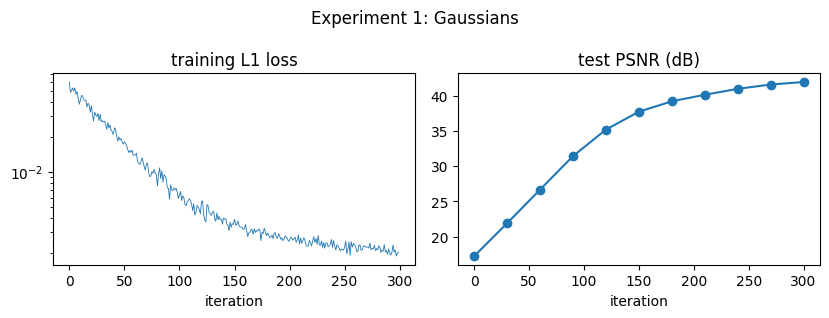

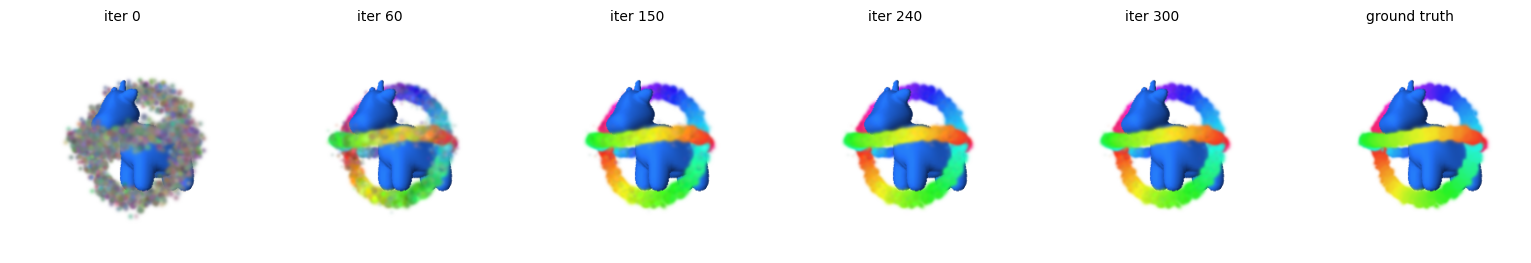

In [7]:
hist_gaussians = train(train_gaussians=True, train_mesh=False, iters=300, snapshot_every=30)
plot_history(hist_gaussians, 'Experiment 1: Gaussians')
show_progress(hist_gaussians)

### Experiment 2: train the mesh (Gaussians fixed)

The mesh starts translated by `(0.12, -0.08, 0.10)` with gray vertex colors. The translation can only be recovered through gradients w.r.t. the vertex positions: silhouettes (antialiasing), the mesh depth against the Gaussians (soft depth test), and the interpolation of the colors.

iter    20 | loss 0.0293 | test PSNR  19.55 dB | mesh translation error 0.1327 | 0.5s
iter    40 | loss 0.0230 | test PSNR  20.90 dB | mesh translation error 0.1005 | 1.0s
iter    60 | loss 0.0194 | test PSNR  22.16 dB | mesh translation error 0.0751 | 1.4s
iter    80 | loss 0.0154 | test PSNR  23.36 dB | mesh translation error 0.0553 | 1.9s
iter   100 | loss 0.0112 | test PSNR  24.39 dB | mesh translation error 0.0426 | 2.4s
iter   120 | loss 0.0112 | test PSNR  25.48 dB | mesh translation error 0.0316 | 2.8s
iter   140 | loss 0.0094 | test PSNR  26.37 dB | mesh translation error 0.0243 | 3.3s
iter   160 | loss 0.0084 | test PSNR  27.13 dB | mesh translation error 0.0190 | 3.7s


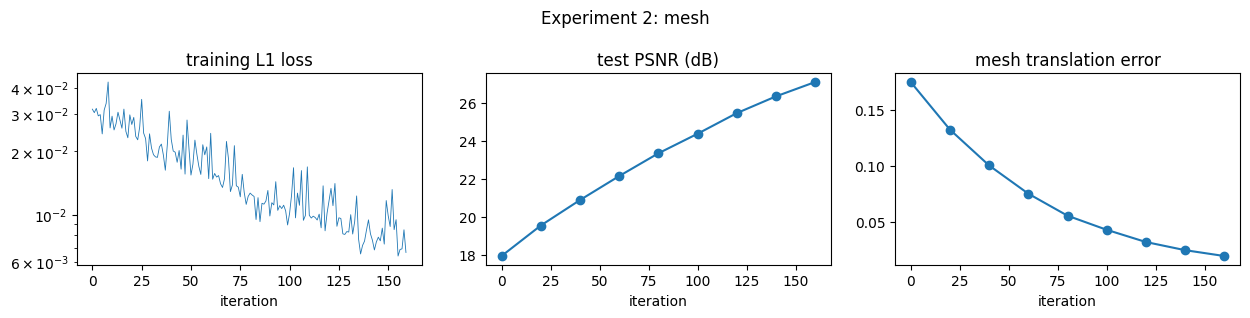

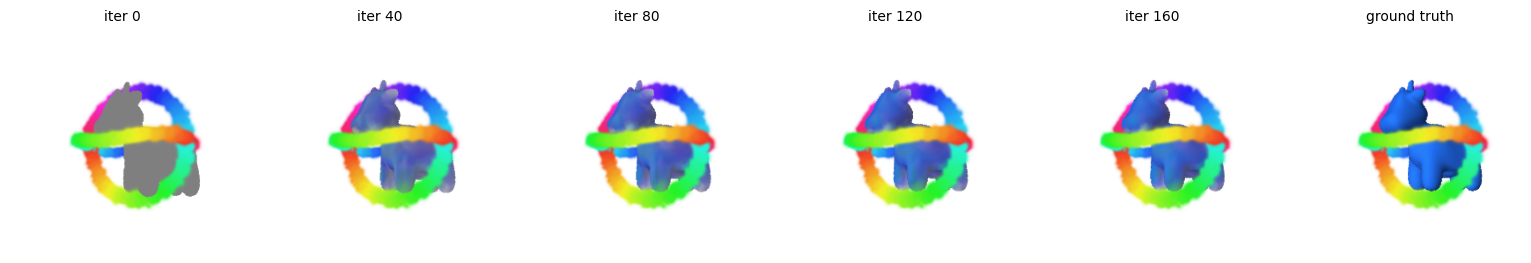

In [8]:
hist_mesh = train(train_gaussians=False, train_mesh=True, iters=160, snapshot_every=20)
plot_history(hist_mesh, 'Experiment 2: mesh', show_translation=True)
show_progress(hist_mesh)

### Experiment 3: train both at once

iter    30 | loss 0.0617 | test PSNR  18.35 dB | mesh translation error 0.1152 | 0.8s
iter    60 | loss 0.0374 | test PSNR  21.45 dB | mesh translation error 0.0668 | 1.6s
iter    90 | loss 0.0221 | test PSNR  24.87 dB | mesh translation error 0.0257 | 2.5s
iter   120 | loss 0.0131 | test PSNR  28.45 dB | mesh translation error 0.0029 | 3.2s
iter   150 | loss 0.0090 | test PSNR  30.77 dB | mesh translation error 0.0010 | 4.0s
iter   180 | loss 0.0065 | test PSNR  32.42 dB | mesh translation error 0.0011 | 4.8s
iter   210 | loss 0.0057 | test PSNR  33.86 dB | mesh translation error 0.0005 | 5.6s
iter   240 | loss 0.0048 | test PSNR  35.07 dB | mesh translation error 0.0003 | 6.4s
iter   270 | loss 0.0044 | test PSNR  35.98 dB | mesh translation error 0.0002 | 7.1s
iter   300 | loss 0.0038 | test PSNR  36.63 dB | mesh translation error 0.0001 | 7.9s


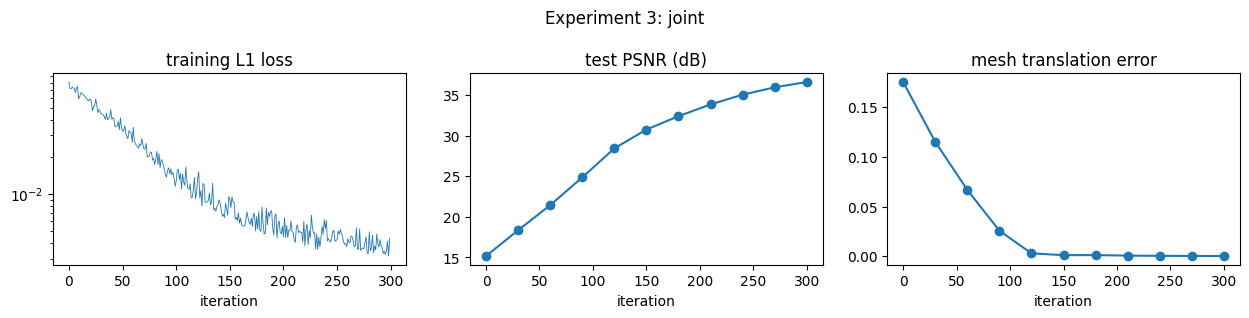

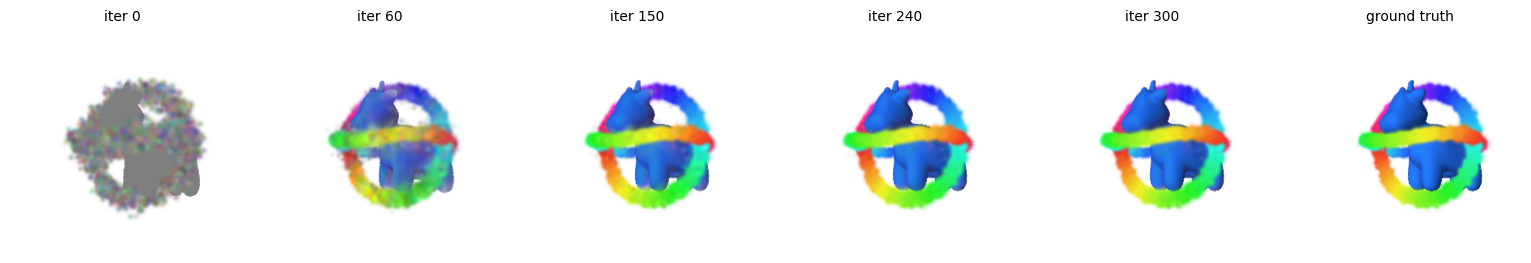

In [9]:
hist_joint = train(train_gaussians=True, train_mesh=True, iters=300, snapshot_every=30)
plot_history(hist_joint, 'Experiment 3: joint', show_translation=True)
show_progress(hist_joint)

### Summary

A run "works" if the test PSNR clearly improves (here: by more than 3 dB) and, when the mesh is trained, its translation error shrinks (here: by more than 80%).

In [10]:
for name, h, mesh_trained in [('gaussians', hist_gaussians, False), ('mesh', hist_mesh, True), ('joint', hist_joint, True)]:
    line = f"{name:10s} test PSNR {h['psnr'][0]:6.2f} -> {h['psnr'][-1]:6.2f} dB"
    ok = h['psnr'][-1] > h['psnr'][0] + 3.0
    if mesh_trained:
        line += f" | mesh translation error {h['t_err'][0]:.4f} -> {h['t_err'][-1]:.4f}"
        ok = ok and h['t_err'][-1] < 0.2 * h['t_err'][0]
    print(line + ('   [OK]' if ok else '   [CHECK]'))

gaussians  test PSNR  17.26 ->  41.95 dB   [OK]
mesh       test PSNR  17.94 ->  27.13 dB | mesh translation error 0.1755 -> 0.0190   [OK]
joint      test PSNR  15.18 ->  36.63 dB | mesh translation error 0.1755 -> 0.0001   [OK]
